# Gaming, and definitions that resist it: how is a paid number gamed, and which line of a definition stops each way?

**Week 4, Monday, chapter 5 of 11, concept chapter 5 of 6.** The topic, in the curriculum's words: *Gaming, and definitions that resist it*. Every number in this notebook is invented for the chapter and small enough to count by hand. It is read from a table the day's generator wrote to `data/`, and the code only confirms the count.

**Who needs the answer.** The owner of Balaji Kirana (invented), who pays the delivery boy Rs 20 for each delivery marked done in the shop's app and promises customers delivery within 30 minutes: a count the boy controls pays him for parcels nobody received. After the break, Uber's city head and finance partner, whose scheme pays a top-up on hours the driver controls.

**The questions on the way.**

1. What do the shop's four weeks of orders hold?
2. How many deliveries did the boy mark done, and how many did customers confirm?
3. What does each count pay, and what does on time read on each clock?
4. Where do the month's complaints sit, found a second way?
5. Which line of a definition stops each way of gaming?
6. What does a resistant pay rule pay, in your turn?

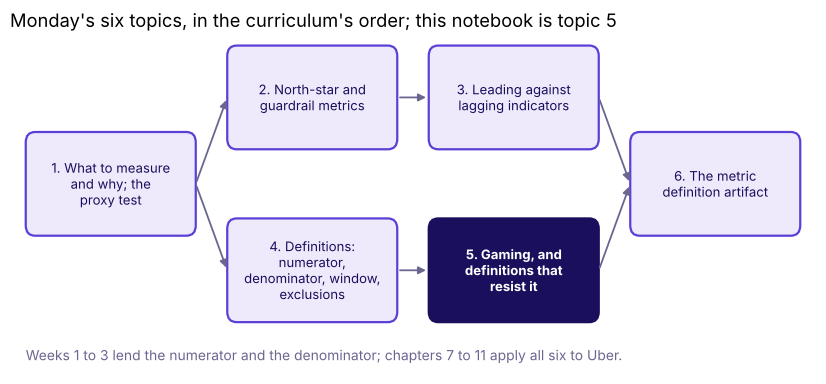

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

from matplotlib.patches import FancyBboxPatch, Patch

TOPICS = ["1. What to measure\nand why; the\nproxy test", "2. North-star and\nguardrail metrics",
          "3. Leading against\nlagging indicators", "4. Definitions:\nnumerator,\ndenominator, window,\nexclusions",
          "5. Gaming, and\ndefinitions that\nresist it", "6. The metric\ndefinition artifact"]
PLACE = [(1.6, 2.25), (4.8, 3.5), (8.0, 3.5), (4.8, 1.0), (8.0, 1.0), (11.2, 2.25)]
LINKS = [(0, 1), (1, 2), (0, 3), (3, 4), (2, 5), (4, 5)]


def topic_map(lit):
    """Monday's six topics in the curriculum's order, joined as the deck's concept map joins them."""
    fig, ax = plt.subplots(figsize=(10.4, 4.4))
    w, h = 2.7, 1.5
    for a, b in LINKS:
        (xa, ya), (xb, yb) = PLACE[a], PLACE[b]
        ax.annotate("", xy=(xb - w / 2, yb), xytext=(xa + w / 2, ya),
                    arrowprops={"arrowstyle": "-|>", "color": MUTED, "lw": 1.3})
    for i, ((x, y), label) in enumerate(zip(PLACE, TOPICS), start=1):
        on = i == lit
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.15",
                                    fc=INK if on else "#EEEAFB", ec=INK if on else VIOLET, lw=1.6))
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5, color="white" if on else INK,
                fontweight="bold" if on else "normal")
    ax.text(0.25, -0.3, "Weeks 1 to 3 lend the numerator and the denominator; chapters 7 to 11 apply all six to Uber.",
            fontsize=10, color=MUTED)
    ax.set_xlim(0, 12.8)
    ax.set_ylim(-0.5, 4.4)
    ax.axis("off")
    ax.set_title(f"Monday's six topics, in the curriculum's order; this notebook is topic {lit}", loc="left")
    plt.show()

topic_map(5)

## What do the shop's four weeks of orders hold?

**Gaming** is raising a number without doing what it stands for. It needs no dishonesty: a paid
number pulls behaviour toward it, and people move with the pull. Balaji Kirana (invented), a
corner shop in Hyderabad, delivers the orders it bills. For each order the table records whether
the boy marked it done in the shop's app, whether the customer confirmed it with the OTP, the
one-time code read out at the door, the minutes from the dispatch time the boy types to the done
press, the minutes from the shop's bill to the done press, and whether the customer complained.
This cell loads the 50 orders and prints every row.

In [2]:
orders = pd.read_csv("../data/C2_W04_D01_kirana_deliveries_STUDENT.csv")
print("Balaji Kirana's four weeks of home deliveries, every order invented for this chapter:")
print(orders.to_string(index=False))
check("50 orders over four weeks", len(orders) == 50 and orders["week"].nunique() == 4)
check("the boy marked every order done", orders["marked_done"].all())

Balaji Kirana's four weeks of home deliveries, every order invented for this chapter:
order_id  week  day  marked_done  otp_confirmed  minutes_from_typed_dispatch  minutes_from_bill  complaint
     K01     1    1         True           True                           25                 15      False
     K02     1    1         True           True                           26                 22      False
     K03     1    1         True          False                           11                 34      False
     K04     1    2         True           True                           20                 42      False
     K05     1    2         True           True                           12                 41      False
     K06     1    3         True          False                            9                 21      False
     K07     1    5         True           True                            9                 25      False
     K08     1    5         True           True           

## What can rise with no parcel changing hands?

**Predict before you run.** The boy marked all 50 orders done, so he is paid Rs 1,000. Against
the deliveries customers confirmed with their OTP, what does the shop find?

a) The same 50: a delivery marked is a delivery made.
b) Fewer than 50: some were marked at the gate and never handed over.
c) More than 50: customers confirm orders he forgot to mark.
d) It cannot be told: the app keeps no second record.

The next cell counts by hand from the table's columns, one line per step: the True values in
`marked_done` and in `otp_confirmed`, and the minutes of 30 or under in each clock column. Then
it counts by code and checks that the two agree.

In [3]:
# By hand, one line per step, from the columns of the table above
hand_marked = 50                 # True in marked_done: every order
hand_confirmed = 40              # True in otp_confirmed
hand_pay_marked = 50 * 20        # Rs 1,000 paid on the boy's count
hand_pay_confirmed = 40 * 20     # Rs 800 on the customer's count
hand_ontime_typed = 50 / 50      # 30 minutes or under from the time the boy types: every order
hand_ontime_bill = 35 / 50       # 30 minutes or under from the shop's bill: 35 orders

# By code, from every row
counted = {"marked": int(orders["marked_done"].sum()), "confirmed": int(orders["otp_confirmed"].sum())}
pay = {who: 20 * n for who, n in counted.items()}
ontime = {"typed": (orders["minutes_from_typed_dispatch"] <= 30).mean(),
          "bill": (orders["minutes_from_bill"] <= 30).mean()}
print("deliveries:", counted, " pay, Rs:", pay, " on time:", ontime)
check("hand and code agree: 50 marked done and 40 confirmed, Rs 1,000 against Rs 800",
      (counted["marked"], counted["confirmed"], pay["marked"], pay["confirmed"])
      == (hand_marked, hand_confirmed, hand_pay_marked, hand_pay_confirmed))
check("hand and code agree: on time 1.00 on the boy's clock and 0.70 on the shop's",
      (ontime["typed"], ontime["bill"]) == (hand_ontime_typed, hand_ontime_bill))

deliveries: {'marked': 50, 'confirmed': 40}  pay, Rs: {'marked': 1000, 'confirmed': 800}  on time: {'typed': np.float64(1.0), 'bill': np.float64(0.7)}
PASS hand and code agree: 50 marked done and 40 confirmed, Rs 1,000 against Rs 800
PASS hand and code agree: on time 1.00 on the boy's clock and 0.70 on the shop's


**What happened.** The answer is b: the boy marked 50 done and customers confirmed 40, so pay on
his count is Rs 1,000 and on theirs Rs 800. The Rs 200 gap is the gaming: 10 orders were marked
done at the gate and never handed over. His clock reads every order on time because he types the
dispatch time himself; the shop's bill clock reads 35 of 50, 0.70. The plausible wrong belief is
a: if we pay per delivery, we get more deliveries.

## Whose counts read higher?

This cell draws the two pairs of counts: pay on the boy's count against the customer's, and on
time by the boy's clock against the shop's.

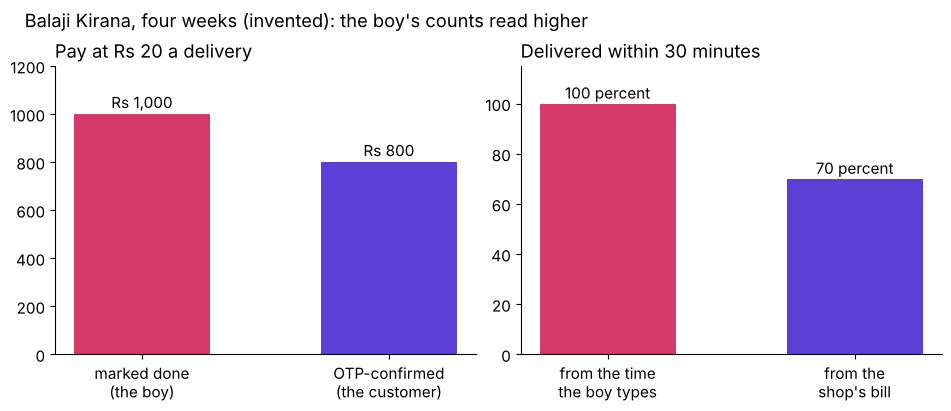

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.4, 4.0), layout="constrained")
a1.bar(["marked done\n(the boy)", "OTP-confirmed\n(the customer)"], [pay["marked"], pay["confirmed"]],
       color=[ROSE, VIOLET], width=0.55)
for i, v in enumerate([pay["marked"], pay["confirmed"]]):
    a1.text(i, v + 25, f"Rs {v:,}", ha="center")
a1.set_ylim(0, 1200)
a1.set_title("Pay at Rs 20 a delivery", loc="left")
a2.bar(["from the time\nthe boy types", "from the\nshop's bill"], [100 * ontime["typed"], 100 * ontime["bill"]],
       color=[ROSE, VIOLET], width=0.55)
for i, v in enumerate([100 * ontime["typed"], 100 * ontime["bill"]]):
    a2.text(i, v + 2, f"{v:.0f} percent", ha="center")
a2.set_ylim(0, 115)
a2.set_title("Delivered within 30 minutes", loc="left")
fig.suptitle("Balaji Kirana, four weeks (invented): the boy's counts read higher", x=0.02, ha="left")
plt.show()

Both of the boy's counts read better than the counts the customer and the shop keep.

## Where do the complaints sit, found a second way?

The first route found the gap by counting OTPs. The second starts from the customers: this cell
matches the month's 6 complaints to the orders, then writes the resisting rule as a short
function. A delivery counts for pay only with a receipt, the customer's OTP, and only when it is
on time by a clock the system starts, the shop's bill.

               orders  complaints
no OTP             10           6
OTP-confirmed      40           0
on the boy's count and clock: 50 deliveries; with a receipt and the shop's clock: 30


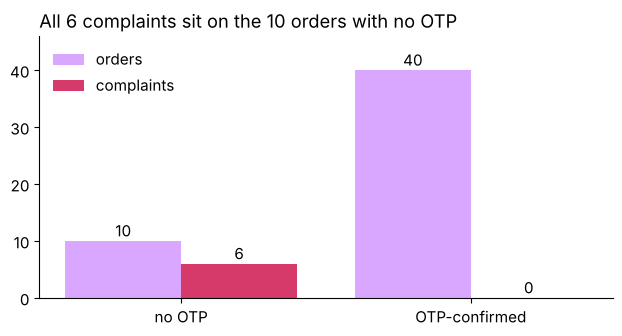

PASS all 6 complaints sit on the 10 orders with no OTP
PASS the resistant rule counts 30 deliveries where the gamed one counts 50


In [5]:
by_receipt = orders.groupby("otp_confirmed")["complaint"].agg(orders="size", complaints="sum")
by_receipt.index = ["no OTP", "OTP-confirmed"]
print(by_receipt)

def paid_deliveries(orders, receipt=True, clock="minutes_from_bill", limit=30):
    """Deliveries that count for pay: OTP-confirmed when receipt is True, and done within the limit on the clock."""
    done = orders["otp_confirmed"] if receipt else orders["marked_done"]
    return int((done & (orders[clock] <= limit)).sum())

gamed = paid_deliveries(orders, receipt=False, clock="minutes_from_typed_dispatch")
resistant = paid_deliveries(orders)
print(f"on the boy's count and clock: {gamed} deliveries; with a receipt and the shop's clock: {resistant}")
fig, ax = plt.subplots(figsize=(7.4, 3.4))
ax.bar([-0.2, 0.8], by_receipt["orders"], width=0.4, color=LAV, label="orders")
ax.bar([0.2, 1.2], by_receipt["complaints"], width=0.4, color=ROSE, label="complaints")
for x, v in zip([-0.2, 0.8, 0.2, 1.2], list(by_receipt["orders"]) + list(by_receipt["complaints"])):
    ax.text(x, v + 0.8, str(v), ha="center")
ax.set_xticks([0, 1], by_receipt.index)
ax.set_ylim(0, 46)
ax.legend(frameon=False, loc="upper left")
ax.set_title("All 6 complaints sit on the 10 orders with no OTP", loc="left")
plt.show()
check("all 6 complaints sit on the 10 orders with no OTP",
      by_receipt.loc["no OTP"].tolist() == [10, 6] and by_receipt.loc["OTP-confirmed", "complaints"] == 0)
check("the resistant rule counts 30 deliveries where the gamed one counts 50", (gamed, resistant) == (50, 30))

**What happened.** All 6 complaints sit on the 10 orders with no OTP and none on the 40 the
customers confirmed, so the second route finds the same 10 orders. The function shows two lines
doing the work: the receipt condition cuts the count from 50 to 40, and the shop's clock cuts it
to the 30 confirmed deliveries made within 30 minutes of the bill.

**The trap.** The owner raises the rate to Rs 25 for each delivery marked done, to motivate the
boy: four weeks then cost 50 x Rs 25 = Rs 1,250 while 40 parcels still reach customers. The check
that catches it is the OTP column; the fix is a receipt condition in the numerator, a count the
person served confirms.

## Which line of a definition stops each way of gaming?

Named last: a definition **resists gaming** when its numerator needs a receipt, its denominator
is set by someone other than the people paid, its clock starts at a time the system records, its
exclusions are dated, and it says what it does not reward. The four ways the shop shows, each
with the public record where it happened and the line that stops it:

| How it is gamed | At Balaji Kirana (invented) | In public | The line that stops it |
|---|---|---|---|
| The paid person controls the count | The boy presses done | Uber's case: an open app counts as online (chapter 7) | A count the person served confirms |
| No receipt or use is needed | Done with no OTP | Wells Fargo counted accounts nobody used | A receipt condition in the numerator |
| The person timed sets the clock's start | The boy types the dispatch time | US Veterans Affairs schedulers typed a "desired date" | A window that starts at the system's time |
| A quiet change of definition | The shop starts counting attempts | Wells Fargo added remittance accounts to its count in 2013 without telling investors | Exclusions and changes dated on the page |

### Your turn: what does the resistant rule pay?

At Rs 20 a delivery, what does the boy earn for the four weeks when only OTP-confirmed deliveries
made within 30 minutes of the shop's bill count? In the empty cell below, fill the two blanks and
run it:

```python
resistant_pay_rs = 20 * paid_deliveries(orders, receipt=____, clock="____")
```

The check under it compares your number with the reference, and shows the reference only once
your number exists. Then say in one sentence what the rule does not reward.

In [6]:
mine = globals().get("resistant_pay_rs")
if mine is None:
    print("Store resistant_pay_rs in the empty cell above, then run this cell again.")
else:
    ref = 20 * paid_deliveries(orders)
    print(f"reference: Rs {ref:,}; yours: Rs {mine:,}")
    print("matches" if mine == ref else "not yet: which column is the receipt, and which clock does the shop start?")

Store resistant_pay_rs in the empty cell above, then run this cell again.


## What does chapter 5 leave?

1. The shop's four weeks (invented) hold 50 orders, all marked done by the boy and 40 confirmed
   by the customer's OTP.
2. Pay reads Rs 1,000 on the boy's count and Rs 800 on the customer's; on time reads 1.00 on his
   clock and 0.70 on the shop's.
3. All 6 complaints sit on the 10 orders with no OTP, so a second route finds the same gaming.
4. `paid_deliveries(orders)` counts with a receipt and a system clock, and counts 30 where the
   boy's own count and clock read 50.
5. Each way of gaming has a line that stops it: a receipt, a denominator the paid person does not
   set, a system clock, dated exclusions, and a line on what the number does not reward.

**The rules.**

- Let the person served confirm the count, as an OTP does.
- Start the clock at a time the system records, never at one the person timed types in.
- Date every change to what is counted, and print the change beside the number.
- Say in one line what the number deliberately does not reward.

**In the interview.** [F] What makes a metric gameable, and how do you write one that is not?

**Where it goes next.** Notebook 06 puts the lines on one page. After the break,
`C2_W04_D01_08_denominators_on_full_data_STUDENT.ipynb` finds Uber drivers logging hours with no
trip, a count the driver controls, and `C2_W04_D01_09_north_star_guardrails_cost_STUDENT.ipynb`
prices what paying for it cost.